#  Modelling Bitcoin Adoption as a Diffusion Process




## Abstract

This analysis asks whether the growth of Bitcoin's active user base follows the pattern of a Bass diffusion model. We derive the model from first principles, solved in closed form, and solved with Euler and Heun schemes. Calibrating the closed form to weekly active-address data by non-linear least squares gives a good fit, with $R^2 = 0.914$. Growth is overwhelmingly imitation-driven, and the model settles at a long-run level of roughly 600,000 addresses, a figure the bootstrap shows is far more tightly constrained than the individual fitted parameters.

## Introduction

Bitcoin's active user base grew without a company marketing it or a coordinated launch. Growth came instead from a mix of independent discovery, prompted by events such as media coverage and price shocks (Sergio and Wedemeier, 2025), and from the pull of existing users drawing new ones in. That pattern, part external prompting and part word of mouth, governs the spread of many new technologies and can be captured formally.

Bitcoin adoption also carries stakes beyond internet culture. In economies undergoing currency crises it has been presented as a hedge against inflation and a route to financial services for the unbanked (Sergio and Wedemeier, 2025). El Salvador's 2021 decision to make it legal tender (Legislative Assembly of El Salvador, 2021) and the United States' approval of spot Bitcoin exchange-traded funds in January 2024 (Gensler, 2024) moved it from a niche network into a matter of national policy.

This analysis asks a narrower, answerable question: does the growth of Bitcoin's active user base follow the pattern a standard diffusion model predicts, and what does fitting that model to real data suggest about where adoption now stands.

## The Bass Diffusion Model: A Framework for Technology Adoption

Bass (1969) developed this model to forecast the market penetration of new consumer durables from early sales data, before a product's full adoption curve had played out. It splits adopters into innovators, who adopt independently of how many others already have, and imitators, who adopt because others have. Every adopter belongs to one type or the other, and there is no route out of the adopted state, since Bass modelled a one-off purchase.

This differs from epidemic models such as SIR, which allow individuals to leave the infected state through recovery, whereas the base Bass model treats adoption as permanent. The innovation and imitation channels map onto the two growth mechanisms from the introduction: outside prompting, and existing users drawing new ones in.

## Defining Variables and Parameters

$t$: Time, measured in days since the start of the address-history series (3 January 2009).

$A(t)$: Active Addresses, the number of unique Bitcoin addresses active in a given period. The dependent variable throughout the model.

$m$: Ceiling parameter, the notional maximum number of active addresses the network could sustain. Treated as constant.

$p$: Coefficient of Innovation, the rate at which addresses become active independently of how many addresses are already active.

$q$: Coefficient of Imitation, the rate at which addresses become active as a result of contact with, or influence from, addresses that are already active.

$d$: Churn/Dormancy Rate, the rate at which already-active addresses become inactive again and drop out of the active count.

## Assumptions of the Model

Constant Innovation, Imitation and Churn Rates: $p$, $q$ and $d$ are treated as fixed over the whole seventeen-year series, despite real-world events such as halvings, exchange collapses or ETF approval that shifted them. Constant rates keep the model tractable and match the level of the ODE being fitted; allowing them to vary would require a different, more complex model.

Fixed Ceiling Parameter: $m$ is treated as constant, representing a notional maximum at the current stage of the network's infrastructure and reach, rather than one that itself grows over time as, for instance, internet access or exchange availability expands globally.

Active Addresses as a Proxy for Users: the model treats $A(t)$ as the count of adopters, but the underlying data measures active addresses, not people. One person can control many addresses, and a single exchange wallet can represent thousands of users, so $A(t)$ is best read as a correlated proxy for adoption rather than a literal headcount.

Churn Included Directly: rather than treating the gap between daily-active addresses and cumulative adopters as unaddressed noise, the model carries an explicit outflow so that addresses can leave the active state as well as enter it. A consequence, returned to once the model is calibrated, is that the long-run active count settles below $m$, since a steady rate of departure prevents the network from ever fully saturating the addressable market.

## Deriving the Model

New activity in the active-address count comes from two separate channels, and each can be reasoned about independently before they are added together.

The first channel needs no contact with existing users at all: some fraction of the addresses that have not yet become active will do so anyway, prompted by outside events such as media coverage or price movements. At any point in time, the pool of addresses still available to convert this way is $m$ minus the current count, $m - A(t)$. A larger remaining pool means proportionally more raw material for this channel to draw on, so the rate at which it contributes new activity is a constant fraction of that pool, $p(m - A(t))$.

The second channel needs contact with an existing user. An address cannot be drawn in by word of mouth unless there is both an already-active address to do the drawing and an inactive one available to be drawn in, so this rate has to scale with the size of both groups at once, in the same way an interaction term between two groups always does. Multiplying $A(t)$ directly by $(m - A(t))$ would make this term grow with the absolute size of the network rather than with how saturated it already is, so it is instead scaled by $A(t)/m$, the fraction of the ceiling already reached: $q\dfrac{A(t)}{m}(m - A(t))$. This keeps $q$ comparable across networks of different sizes, and means the imitation channel contributes most partway through adoption, when there are simultaneously many active addresses to imitate and many inactive ones left to convert, rather than at the very start or the very end.

An address becomes active through one channel or the other, not both, so the two rates are added rather than combined any other way, giving the base governing equation.

$$\frac{dA}{dt} = p(m - A) + q\,\frac{A}{m}\,(m - A)$$

The base equation assumes that once an address becomes active it stays active, but an active-address count is a snapshot rather than a running total, and addresses fall dormant as wallets are abandoned or consolidated. A third channel therefore removes activity rather than adding it. The number of addresses available to fall dormant at any moment is the active count itself, so this outflow is a constant fraction of that count, $-d\,A(t)$. This mirrors the recovery term in epidemic models lik SIR, where a fixed proportion of those in the infected state leave it in each period, and it is the one term that pulls the active count down rather than up, giving the extended governing equation.

$$\frac{dA}{dt} = p(m - A) + q\,\frac{A}{m}\,(m - A) - d\,A$$

In [1]:
# Importing necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp
from ipywidgets import interact, FloatSlider


## Solving the Bass Model

### Solving Symbolically

The base equation is a Riccati equation with constant coefficients and has an exact analytic solution, which serves as a benchmark for the numerical schemes introduced later. The natural initial condition is $A(0)=0$.

Defining the symbols, the function $A(t)$, and the governing ODE:

In [2]:
# Defining variables
t = sp.Symbol('t')
p = sp.Symbol('p', positive=True)
q = sp.Symbol('q', positive=True)
m = sp.Symbol('m', positive=True)

# Defining the function object
A = sp.Function('A')(t)

# Defining the governing ODE
# dA/dt = p*(m - A) + q*(A/m)*(m - A)
bass_ode = sp.Eq(A.diff(t), p*(m - A) + q*(A/m)*(m - A))
bass_ode


Eq(Derivative(A(t), t), p*(m - A(t)) + q*(m - A(t))*A(t)/m)

Solving the ODE symbolically, with the initial condition $A(0)=0$:

In [3]:
# Solve the base model in closed form, setting A(0) = 0.
# sympy's raw ics solution comes back in a complex-logarithm form (it contains log(-p/q))
# that evaluates to nan under real arithmetic, so the equivalent clean real form is written
# out by hand below and verified against the ODE in the next cell.
A_sol_raw = sp.dsolve(bass_ode, A, ics={A.subs(t, 0): 0})

base_sol = sp.Eq(A, m * (1 - sp.exp(-(p + q) * t)) / (1 + (q / p) * sp.exp(-(p + q) * t)))
base_sol


Eq(A(t), m*(1 - exp(t*(-p - q)))/(1 + q*exp(t*(-p - q))/p))

In [4]:
# Checking the clean closed form. The parameter values here only verify the algebra;
# they are arbitrary and are not Bitcoin figures.
base_rhs = base_sol.rhs
residual_base = sp.simplify(
    base_rhs.diff(t) - (p * (m - base_rhs) + q * (base_rhs / m) * (m - base_rhs))
)
print("Base: ODE residual simplifies to:", residual_base)
print("Base: A(0) =", sp.simplify(base_rhs.subs(t, 0)))
print("Base: limit as t -> infinity =", sp.limit(base_rhs, t, sp.oo))

_pv, _qv, _mv = 0.02, 0.3, 1000.0                   
_f = sp.lambdify(t, base_rhs.subs({p: _pv, q: _qv, m: _mv}), "numpy")
_sol = solve_ivp(lambda tt, a: _pv * (_mv - a) + _qv * (a / _mv) * (_mv - a),
                 [0, 300], [0.0], t_eval=np.linspace(0, 300, 13), rtol=1e-10, atol=1e-10)
print(f"Base: max abs error vs solve_ivp = {np.max(np.abs(_sol.y[0] - _f(_sol.t))):.2e}")


Base: ODE residual simplifies to: 0
Base: A(0) = 0
Base: limit as t -> infinity = m
Base: max abs error vs solve_ivp = 9.06e-08


With the initial condion $A(0)=0$ yields the closed form

$$A(t)=\frac{m\left(1-e^{-(p+q)t}\right)}{1+\frac{q}{p}\,e^{-(p+q)t}}.$$

Substituting it back into the governing equation reduces the difference to zero. At $t=0$ it gives $A(0)=0$, and as $t\to\infty$ the exponential terms decay so $A(t)\to m$: the base model saturates at $m$.

### Solving the Churn-Extended Model

The same treatment is applied to the extended equation. Here sympy's solver returns only a degenerate branch and cannot impose the initial condition, so the solution is instead built from the model's two equilibria, the values of $A$ at which growth stops.

In [5]:
# Extended model with churn.
d = sp.Symbol('d', positive=True)
churn_ode = sp.Eq(A.diff(t), p * (m - A) + q * (A / m) * (m - A) - d * A)

print("dsolve without an initial condition returns a degenerate branch:")
print("   ", sp.dsolve(churn_ode, A).rhs)
try:
    sp.dsolve(churn_ode, A, ics={A.subs(t, 0): 0})
except Exception as e:
    print("dsolve with A(0) = 0 fails:", f"{type(e).__name__}: {e}")

# Equilibria method: roots of the constant-coefficient quadratic dA/dt = a2*A**2 + a1*A + a0
X = sp.Symbol('X')
a2, a1, a0 = -q / m, q - p - d, p * m
r1, r2 = sp.solve(sp.Eq(a2 * X**2 + a1 * X + a0, 0), X)
k = a2 * (r1 - r2)
A_churn = r1 * r2 * (sp.exp(k * t) - 1) / (r1 * sp.exp(k * t) - r2)
churn_sol = sp.Eq(A, A_churn)
churn_sol


dsolve without an initial condition returns a degenerate branch:


    C1 + t/m


dsolve with A(0) = 0 fails: ValueError: Couldn't solve for initial conditions


Eq(A(t), m**2*(-1 + exp(-q*t*(m*(-d - p + q - sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))/(2*q) - m*(-d - p + q + sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))/(2*q))/m))*(-d - p + q - sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))*(-d - p + q + sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))/(4*q**2*(m*(-d - p + q - sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))*exp(-q*t*(m*(-d - p + q - sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))/(2*q) - m*(-d - p + q + sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))/(2*q))/m)/(2*q) - m*(-d - p + q + sqrt(d**2 + 2*d*p - 2*d*q + p**2 + 2*p*q + q**2))/(2*q))))

In [6]:
# Checking the churn closed form. The parameter values here are arbitrary and are not Bitcoin figures.
residual_churn = sp.simplify(
    A_churn.diff(t) - (p * (m - A_churn) + q * (A_churn / m) * (m - A_churn) - d * A_churn)
)
print("Churn: ODE residual simplifies to:", residual_churn)
print("Churn: A(0) =", sp.simplify(A_churn.subs(t, 0)))
print("Churn: dA/dt at A = m is", sp.simplify((p * (m - A) + q * (A / m) * (m - A) - d * A).subs(A, m)))

_pv, _qv, _mv, _dv = 0.02, 0.3, 1000.0, 0.05        
_fc = sp.lambdify(t, A_churn.subs({p: _pv, q: _qv, m: _mv, d: _dv}), "numpy")
_solc = solve_ivp(lambda tt, a: _pv * (_mv - a) + _qv * (a / _mv) * (_mv - a) - _dv * a,
                  [0, 400], [0.0], t_eval=np.linspace(0, 400, 13), rtol=1e-10, atol=1e-10)
print(f"Churn: max abs error vs solve_ivp = {np.max(np.abs(_solc.y[0] - np.real(_fc(_solc.t)))):.2e}")


Churn: ODE residual simplifies to: 0
Churn: A(0) = 0
Churn: dA/dt at A = m is -d*m
Churn: max abs error vs solve_ivp = 8.40e-08


The extended equation remains a Riccati equation with constant coefficients. Writing it as $\frac{dA}{dt}=a_2A^2+a_1A+a_0$ with $a_2=-q/m$, $a_1=q-p-d$ and $a_0=pm$ gives two equilibria $r_1$ and $r_2$, and in terms of these

$$A(t)=\frac{r_1 r_2\left(e^{kt}-1\right)}{r_1 e^{kt}-r_2},\qquad k=a_2\left(r_1-r_2\right).$$

At $t=0$ the numerator vanishes, so $A(0)=0$ as required, and substituting the expression back into the extended equation again reduces the residual to zero. The long-run level is the positive equilibrium rather than $m$: evaluating the growth rate at $A=m$ gives $\frac{dA}{dt}=-dm$, which is negative for any positive churn rate, so the active count turns downward before reaching $m$, settling strictly below it.

### Calibrating to Real Data

The active-address series is the blockchain.com *Unique Addresses Used* dataset, stored locally at `data/n-unique-addresses.json` (Blockchain.com, n.d.); the market-price series in the same export is not used. This step loads and inspects the data, then calibrates $p$, $q$, $m$ and $d$ against it.

        date  active_addresses
0 2009-01-03                 2
1 2009-01-12               102
2 2009-01-16               110
3 2009-01-20               115
4 2009-01-24               202

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              1599 non-null   datetime64[ms]
 1   active_addresses  1599 non-null   int64         
dtypes: datetime64[ms](1), int64(1)
memory usage: 25.1 KB

Date range: 2009-01-03 to 2026-08-03
Number of observations: 1599


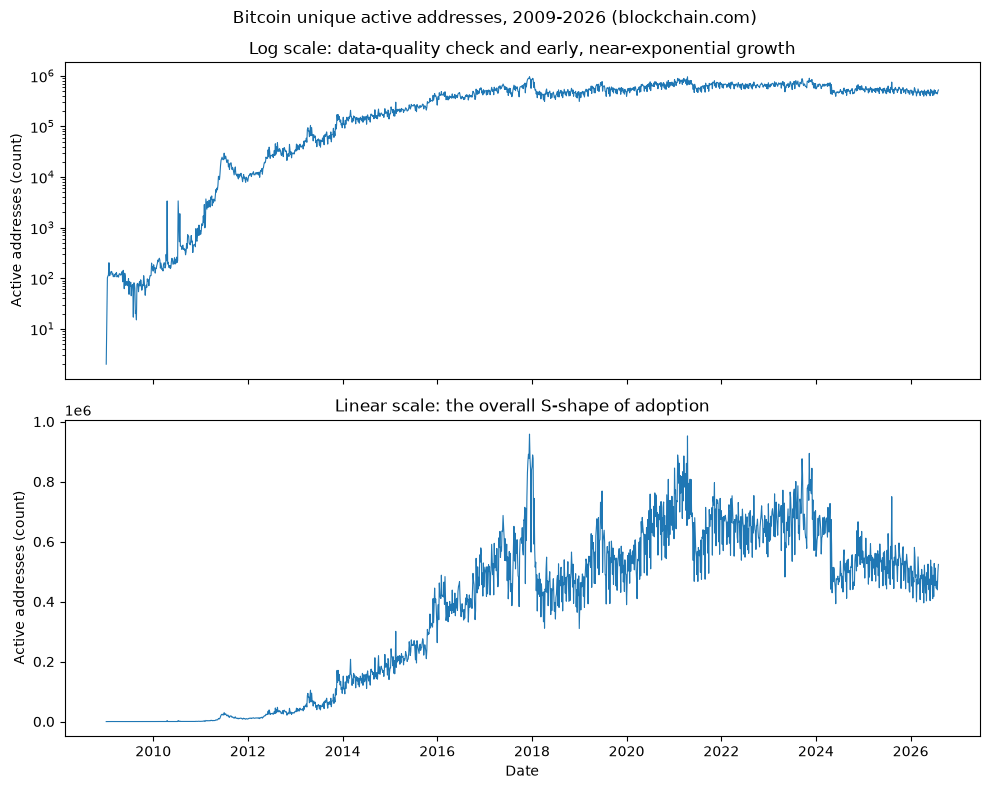

In [7]:
# Loading the blockchain.com "Unique Addresses Used" export (manually downloaded to data/).
# The file bundles two series; only the n-unique-addresses series is used here.
import json

with open("data/n-unique-addresses.json") as f:
    raw = json.load(f)

addresses = pd.DataFrame(raw["n-unique-addresses"])
addresses["date"] = pd.to_datetime(addresses["x"], unit="ms")  # timestamps are in milliseconds
addresses = (
    addresses.rename(columns={"y": "active_addresses"})
    .loc[:, ["date", "active_addresses"]]
    .sort_values("date")
    .reset_index(drop=True)
)

# Inspecting the cleaned series before plotting
print(addresses.head())
print()
addresses.info()
print(f"\nDate range: {addresses['date'].min().date()} to {addresses['date'].max().date()}")
print(f"Number of observations: {len(addresses)}")

# Exploratory plot: same series on two scales, sharing the time axis
fig, (ax_log, ax_lin) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

ax_log.plot(addresses["date"], addresses["active_addresses"], linewidth=0.8)
ax_log.set_yscale("log")
ax_log.set_ylabel("Active addresses (count)")
ax_log.set_title("Log scale: data-quality check and early, near-exponential growth")

ax_lin.plot(addresses["date"], addresses["active_addresses"], linewidth=0.8)
ax_lin.set_ylabel("Active addresses (count)")
ax_lin.set_xlabel("Date")
ax_lin.set_title("Linear scale: the overall S-shape of adoption")

fig.suptitle("Bitcoin unique active addresses, 2009-2026 (blockchain.com)")
fig.tight_layout()
plt.show()

The two panels show the same series on two scales. The logarithmic panel spans six orders of magnitude, from a handful of addresses in 2009 to close to a million, and is better for data quality: points are about four days apart rather than daily, and a few early observations spike far above their neighbours in a then-tiny network. Its near-straight early portion indicates roughly exponential growth; the linear panel shows the eventual S-shape, levelling off after the mid-2010s. An active address remains only a proxy for a person, not a literal headcount.

The raw series is sampled unevenly, at roughly four-day intervals, so it is resampled onto a regular weekly grid, taking each week's mean, with time measured as $t$ days since 3 January 2009. This targets the underlying adoption trend rather than short-term fluctuation.

Fitted p = 7.650e-07 /day
Fitted q = 0.0149 /day
Fitted m = 3,417,241
Fitted d = 0.0123 /day
Long-run ceiling (positive equilibrium) = 599,805
Model-vs-data error: MAE = 53,184, MSE = 6,011,193,126, R^2 = 0.9138


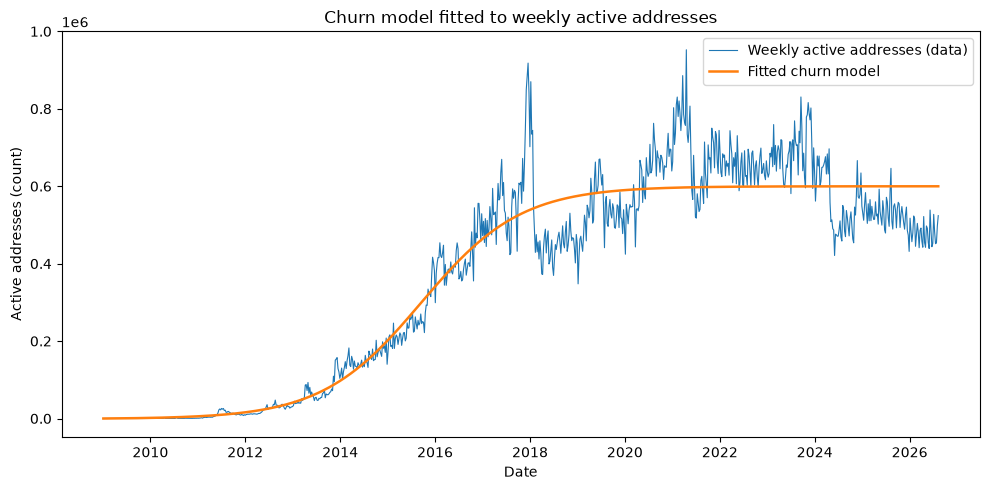

In [8]:
# Resample the cleaned series to a regular weekly grid (mean per week); t = days since 2009-01-03.
weekly = addresses.set_index("date")["active_addresses"].resample("W").mean().dropna()
t_days = (weekly.index - pd.Timestamp("2009-01-03")).days.to_numpy(dtype=float)
y_weekly = weekly.to_numpy(dtype=float)

# Closed-form churn solution, as an explicit function of t and the four parameters.
def churn_closed(t, p, q, m, d):
    a2 = -q / m
    a1 = q - p - d
    a0 = p * m
    disc = np.sqrt(a1**2 - 4 * a2 * a0)
    r1 = (-a1 + disc) / (2 * a2)
    r2 = (-a1 - disc) / (2 * a2)
    k = a2 * (r1 - r2)
    return r1 * r2 * (np.exp(k * t) - 1) / (r1 * np.exp(k * t) - r2)

# Fit p, q, m, d directly against the closed form (no numerical simulation needed).
ymax = y_weekly.max()
p0 = [1e-3, 0.05, ymax * 1.2, 1e-3]
bounds = ([1e-8, 1e-8, ymax, 1e-8], [1.0, 2.0, 50 * ymax, 0.5])
popt, pcov = curve_fit(churn_closed, t_days, y_weekly, p0=p0, bounds=bounds, maxfev=200000)
p_hat, q_hat, m_hat, d_hat = popt

# Model-vs-data error and the long-run ceiling (positive equilibrium of the fitted model).
fit_curve = churn_closed(t_days, *popt)
mae = np.mean(np.abs(y_weekly - fit_curve))
mse = np.mean((y_weekly - fit_curve) ** 2)
r2 = 1 - np.sum((y_weekly - fit_curve) ** 2) / np.sum((y_weekly - y_weekly.mean()) ** 2)
a2, a1, a0 = -q_hat / m_hat, q_hat - p_hat - d_hat, p_hat * m_hat
disc = np.sqrt(a1**2 - 4 * a2 * a0)
ceiling = max((-a1 + disc) / (2 * a2), (-a1 - disc) / (2 * a2))

print(f"Fitted p = {p_hat:.3e} /day")
print(f"Fitted q = {q_hat:.4f} /day")
print(f"Fitted m = {m_hat:,.0f}")
print(f"Fitted d = {d_hat:.4f} /day")
print(f"Long-run ceiling (positive equilibrium) = {ceiling:,.0f}")
print(f"Model-vs-data error: MAE = {mae:,.0f}, MSE = {mse:,.0f}, R^2 = {r2:.4f}")

# Fitted curve against the real weekly data.
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(weekly.index, y_weekly, linewidth=0.8, label="Weekly active addresses (data)")
ax.plot(weekly.index, fit_curve, linewidth=1.8, label="Fitted churn model")
ax.set_xlabel("Date")
ax.set_ylabel("Active addresses (count)")
ax.set_title("Churn model fitted to weekly active addresses")
ax.legend()
fig.tight_layout()
plt.show()


Fitting the closed-form churn solution to the weekly series gives $p\approx7.7\times10^{-7}$, $q\approx0.015$ and $d\approx0.012$ per day, with a ceiling parameter $m$ of around 3.4 million. The model tracks the data with $R^2\approx0.91$ and a mean absolute model-vs-data error of about 53,000 addresses, capturing the rise and later plateau. The parameters are only weakly identified individually: very different values of $m$ leave the curve almost unchanged, so the meaningful quantity is the long-run level, close to 600,000 addresses, well below $m$ as churn requires.

Converged: 200/200 = 100%
  p (/day)   95% CI: [5.152e-07, 9.893e-07]
  q (/day)   95% CI: [0.01475, 0.01546]
  m          95% CI: [3.221e+06, 3.716e+06]
  d (/day)   95% CI: [0.01225, 0.01266]
  ceiling    95% CI: [5.896e+05, 6.13e+05]


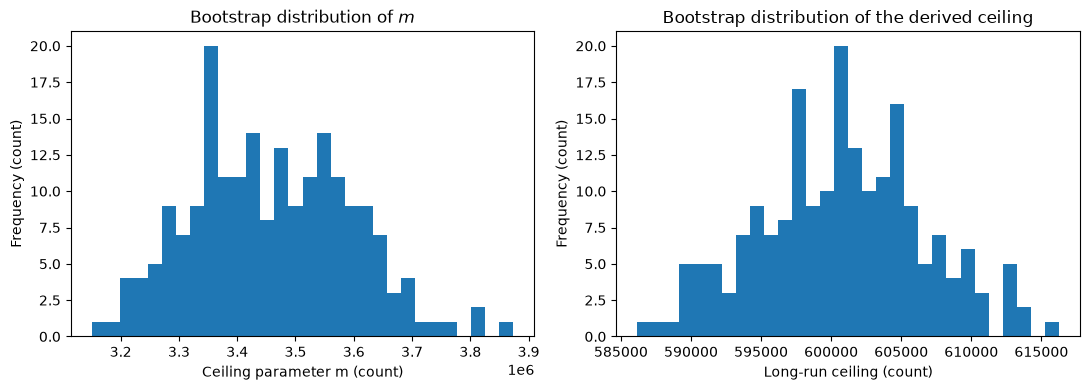

In [9]:
# Bootstrap confidence intervals by resampling the weekly observations with replacement
# and refitting each time, using the fitted values as the starting guess.
rng = np.random.default_rng(0)
n_boot = 200
n_obs = len(t_days)

def equilibrium_ceiling(p, q, m, d):
    a2, a1, a0 = -q / m, q - p - d, p * m
    disc = np.sqrt(a1**2 - 4 * a2 * a0)
    return max((-a1 + disc) / (2 * a2), (-a1 - disc) / (2 * a2))

boot = []          # rows of [p, q, m, d, ceiling]
n_converged = 0
for _ in range(n_boot):
    idx = rng.integers(0, n_obs, n_obs)
    try:
        pb, _ = curve_fit(churn_closed, t_days[idx], y_weekly[idx],
                          p0=popt, bounds=bounds, maxfev=200000)
        boot.append([*pb, equilibrium_ceiling(*pb)])
        n_converged += 1
    except Exception:
        pass  # a single non-convergence does not stop the loop

boot = np.array(boot)
print(f"Converged: {n_converged}/{n_boot} = {n_converged / n_boot:.0%}")
labels = ["p (/day)", "q (/day)", "m", "d (/day)", "ceiling"]
for j, name in enumerate(labels):
    lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
    print(f"  {name:10} 95% CI: [{lo:,.4g}, {hi:,.4g}]")

# Side-by-side distributions of the ceiling parameter m and the derived long-run ceiling.
fig, (ax_m, ax_c) = plt.subplots(1, 2, figsize=(11, 4))
ax_m.hist(boot[:, 2], bins=30)
ax_m.set_xlabel("Ceiling parameter m (count)")
ax_m.set_ylabel("Frequency (count)")
ax_m.set_title("Bootstrap distribution of $m$")
ax_c.hist(boot[:, 4], bins=30)
ax_c.set_xlabel("Long-run ceiling (count)")
ax_c.set_ylabel("Frequency (count)")
ax_c.set_title("Bootstrap distribution of the derived ceiling")
fig.tight_layout()
plt.show()


Resampling the weekly observations with replacement and refitting 200 times converged in every case. The 95% intervals confirm, as anticipated, that the long-run settling level is pinned down more precisely than the individual parameters that produce it. The long-run ceiling sits in a tight band of roughly 590,000 to 613,000 addresses, whereas $p$ spans about a factor of two and $m$ runs from 3.2 to 3.7 million, with 𝑚 pressing against its fitting bound rather than being constrained by the data itself. The rates 𝑞 and 𝑑 are tightly estimated, so the meaningful output is the long-run settling level, not 
𝑚.

### Solving Numerically: Euler's and Heun's Methods

With the parameters fixed at their fitted values, the churn model is also solved numerically. Euler's method steps forward using the slope at the start of each interval; Heun's uses that Euler step as a predictor, then advances with the average of the slopes at the start and predicted point. Both use a seven-day step and are compared against the exact closed form. This error measures how closely the step-by-step approximation tracks the model's own exact curve, a separate question from how well that curve matches the Bitcoin data.

Euler numerical error: MAE = 1,528.6, MSE = 7,545,616.0
Heun  numerical error: MAE = 102.89, MSE = 29,735.91


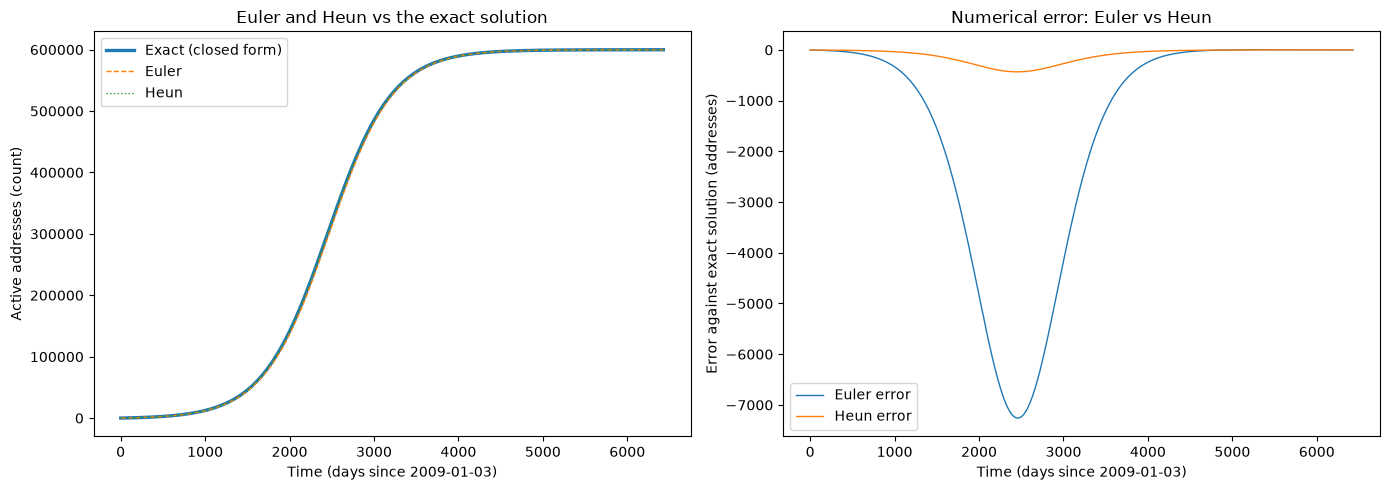

In [10]:
# Euler and Heun applied to the churn model, using the fitted parameters from the calibration above.
def dA_dt(a):
    return p_hat * (m_hat - a) + q_hat * (a / m_hat) * (m_hat - a) - d_hat * a

dt = 7.0
t_grid = np.arange(t_days.min(), t_days.max() + dt, dt)

# Explicit Euler: slope taken at the start of each step.
A_euler = np.zeros_like(t_grid)
for i in range(len(t_grid) - 1):
    A_euler[i + 1] = A_euler[i] + dt * dA_dt(A_euler[i])

# Heun: Euler estimate as predictor, then step with the average of start and predicted slopes.
A_heun = np.zeros_like(t_grid)
for i in range(len(t_grid) - 1):
    slope_start = dA_dt(A_heun[i])
    predictor = A_heun[i] + dt * slope_start
    slope_end = dA_dt(predictor)
    A_heun[i + 1] = A_heun[i] + dt * 0.5 * (slope_start + slope_end)

A_exact = churn_closed(t_grid, *popt)

# Numerical error of each scheme against the exact solution.
mae_euler = np.mean(np.abs(A_euler - A_exact)); mse_euler = np.mean((A_euler - A_exact) ** 2)
mae_heun = np.mean(np.abs(A_heun - A_exact)); mse_heun = np.mean((A_heun - A_exact) ** 2)
print(f"Euler numerical error: MAE = {mae_euler:,.1f}, MSE = {mse_euler:,.1f}")
print(f"Heun  numerical error: MAE = {mae_heun:,.2f}, MSE = {mse_heun:,.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: all three curves overlaid
ax1.plot(t_grid, A_exact, linewidth=2.4, label="Exact (closed form)")
ax1.plot(t_grid, A_euler, linewidth=1.0, linestyle="--", label="Euler")
ax1.plot(t_grid, A_heun, linewidth=1.0, linestyle=":", label="Heun")
ax1.set_xlabel("Time (days since 2009-01-03)")
ax1.set_ylabel("Active addresses (count)")
ax1.set_title("Euler and Heun vs the exact solution")
ax1.legend()

# Right panel: error against exact solution
ax2.plot(t_grid, A_euler - A_exact, linewidth=1.0, label="Euler error")
ax2.plot(t_grid, A_heun - A_exact, linewidth=1.0, label="Heun error")
ax2.set_xlabel("Time (days since 2009-01-03)")
ax2.set_ylabel("Error against exact solution (addresses)")
ax2.set_title("Numerical error: Euler vs Heun")
ax2.legend()

fig.tight_layout()
plt.show()

Against the exact solution, Euler's mean absolute error is about 1,500 addresses and Heun's about 100, so Heun's is roughly fifteen times more accurate at the same step size. The three curves are visually indistinguishable at this scale, so the difference shows in the metrics: Heun's second slope estimate corrects most of the first-order error that Euler's single slope leaves behind.

### Exploring the Model Interactively

The sliders below vary $p$, $q$, $m$ and $d$ around their fitted values and redraw the closed-form churn curve against the weekly data, making the effect of each parameter on the fit visible directly.

In [11]:
# Sliders are centred on the fitted values; m is floored at the largest observed value,
# matching the m > max(observed) constraint used in the calibration.
def plot_model(p, q, m, d):
    undefined = False
    with np.errstate(divide="ignore", invalid="ignore"):
        try:
            curve = churn_closed(t_days, p, q, m, d)
        except ZeroDivisionError:
            undefined = True
    if not undefined and not np.any(np.isfinite(curve)):
        undefined = True

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(weekly.index, y_weekly, ".", markersize=2, alpha=0.5,
            label="Weekly active addresses (data)")
    if undefined:
        ax.text(0.5, 0.5, "Model undefined at this parameter setting",
                transform=ax.transAxes, ha="center", va="center")
    else:
        ax.plot(weekly.index, curve, linewidth=2, label="Closed-form churn model")
    ax.set_xlabel("Date")
    ax.set_ylabel("Active addresses (count)")
    ax.set_title("Interactive churn model vs weekly active addresses")
    ax.legend(loc="upper left")
    plt.show()

interact(
    plot_model,
    p=FloatSlider(value=p_hat, min=0.0, max=2 * p_hat, step=2 * p_hat / 200,
                  readout_format=".2e", description="p"),
    q=FloatSlider(value=q_hat, min=0.0, max=2 * q_hat, step=2 * q_hat / 200,
                  readout_format=".4f", description="q"),
    m=FloatSlider(value=m_hat, min=float(y_weekly.max()), max=2 * m_hat, step=2 * m_hat / 200,
                  readout_format=",.0f", description="m"),
    d=FloatSlider(value=d_hat, min=0.0, max=2 * d_hat, step=2 * d_hat / 200,
                  readout_format=".4f", description="d"),
);


interactive(children=(FloatSlider(value=7.650492925484995e-07, description='p', max=1.530098585096999e-06, rea…

## Limitations

### Limitations of the Model

The model is monotone and settles onto a plateau, so it captures only the average level of the post-2018 data and not its oscillations. a direct consequence of holding 𝑝, 𝑞 and 𝑑 constant across a period in which events such as halvings and the 2024 ETF approval likely shifted them. Weekly resampling is a second limitation of scope, since averaging within each week removes any structure at sub-weekly timescales. The proxy issue raised in the assumptions carries through as well, an active address remaining an imperfect stand-in for a person. Two forms of parameter uncertainty appeared. The bootstrap intervals showed that 𝑝 and 𝑚nwould shift noticeably under different samples of the data, while the derived settling level stayed in a narrow band. Separately, refitting the same data from different starting guesses moved 𝑚 substantially without changing the fitted curve, indicating that many values of 𝑚 produce near-identical predictions. Both findings point the same way the individual parameters, especially 𝑚 are not well determined by this data but the settling level is.

### Limitations of the Conclusions

The fitted curve describes the shape of past growth and does not by itself license the claim that adoption will continue along the same path. Because the innovation rate $p$ is statistically indistinguishable from zero, the data cannot rule out some innovation-driven adoption; it indicates only that word of mouth dominates, not that outside prompting played no part. The figure of around 600,000 active addresses is where this model settles given the fitted parameters, not a hard ceiling on Bitcoin adoption in the world. The model speaks to the shape of an adoption curve, not to the financial-inclusion or speculation questions raised at the outset, and it cannot adjudicate between them.

## Conclusion

The active-address record is described well by a Bass diffusion model with churn, and the fit points to a clear qualitative story. Bitcoin's growth has been driven overwhelmingly by imitation rather than by outside-prompted adoption, and the extended model settles below its nominal ceiling because steady dormancy offsets new activity. That level, around 600,000 weekly active addresses, is the quantity the data constrains most firmly. These findings speak to the shape of adoption and should be read in that light. The introduction set Bitcoin against larger questions of financial infrastructure and speculative interest, and a diffusion model does not settle them: a curve that fits the past describes how adoption spread, not whether the network is durable infrastructure or a passing wave of enthusiasm. That question remains open, and this model is not the instrument to close it.

This work contains 2388 words (prose only, excluding code cells, references and front matter).

## References

Bass, F.M. (1969). A new product growth model for consumer durables. Management Science, 15(5), pp.215–227. doi:https://doi.org/10.1287/mnsc.15.5.215.

Blockchain.com (n.d.). Unique Addresses Used. [online] Available at: https://www.blockchain.com/charts/n-unique-addresses [Accessed 1 August 2026].

Gensler, G. (2024). Statement on the approval of spot Bitcoin exchange-traded products. U.S. Securities and Exchange Commission. [online] Available at: https://www.sec.gov/newsroom/speeches-statements/gensler-statement-spot-bitcoin-011023 [Accessed 3 August 2026].

Legislative Assembly of El Salvador (2021). Bitcoin Law (Ley Bitcoin). Enacted 8 June 2021, effective 7 September 2021. [online] Available at: https://www.ibanet.org/el-salvador-bitcoin-as-legal-tender [Accessed 3 August 2026].

Sergio, I. and Wedemeier, J. (2025). Global surge: exploring cryptocurrency adoption with evidence from spatial models. Financial Innovation, 11(96). doi:https://doi.org/10.1186/s40854-025-00765-0.